# Lorehaven pricing forecast

This notebook forecasts **revenue per customer** and **member count** for the next four seasons (winter to fall 2020) under the prices and discounts you choose.

**How to use it**

1. Change any of the four numbers under **Your pricing choices**.
2. Run the whole notebook (*Run All*). It takes about a minute.
3. Read the result under **The forecast**. It is always compared with today's policy.

Nothing else needs editing.

## What this forecast assumes

The difference between two settings is more reliable than either number on its own.

* **Marketing is frozen at 2019.** Each customer sees the ads they saw in the same season of 2019. This holds fixed both the marketing plan and **how spend turns into ad exposure on each individual customer level**, so the tool cannot evaluate a change in marketing spend. The advanced `AD_PLAN` option only swaps in a past season with similar planned spend as the backdrop; it is still not a spend lever.
* **Prices do not change who sees ads.** Exposure stays the same whatever the prices.
* **Customers respond to price as in 2017–2019.** The response comes from Lorehaven's randomized discounts, so it is cause and effect.
* **Five cut regions only** (357,686 customers). Panem kept \$15 with no offers, so there is no price response to learn there.
* **Starts from real membership at the end of fall 2019** (128,602 members). Each later season builds on the forecast, not on real results.
* **The customer base is fixed.** No one arrives or leaves the market; only membership changes.
* **Your settings give every discount eligible customer the same discount.**
* **Prices stay between \$7 and \$15**, the range ever charged. A caution prints when a setting goes past what was tried.
* **Four more seasons are run for context only,** to show whether a setting's lead holds once the member base adjusts.
* **Revenue, not profit.** Serving and advertising costs are not included.

## Your pricing choices

They apply to all four seasons. No price may go below \$7 or above \$15, the range that has actually been charged.

In [ ]:
BASE_PRICE = 12          # list price for one season, $10 to $15            (today: 12)
JOINING_DISCOUNT = 5     # $ off the first season for non-members who get an offer, 0 to 5   (today: $1-$5 at random)
SHARE_OFFERED = 25       # % of non-members who get that offer each season, 0 to 100         (today: 25)
MEMBER_DISCOUNT = 1      # $ off every season after the first, 0 to 5                        (today: $1-$5 at random, re-drawn each season)

AD_PLAN = None

## Advanced setting (optional)
None = advertising repeats 2019. 
Or a planned (podcast, social) spend for winter, spring, summer and fall 2020, e.g. [(46, 13), (18, 8), (24, 12), (45, 14)]: each season's ad exposure is then copied from the past season at the same time of year with the closest planned spend. A backdrop, not a spend lever.

## Setup

This cell loads the data and the two models from Parts 3 and 4. The code is in `tools_utils.py`; nothing there needs to be read or changed.

In [10]:
import helper.tools_utils as tu

ctx = tu.load(AD_PLAN)

Ready: 357,686 customers in five regions, 128,602 of them members in Fall 2019.


## The forecast

In [3]:
mine = tu.run(ctx, BASE_PRICE, JOINING_DISCOUNT, SHARE_OFFERED, MEMBER_DISCOUNT)

Your choices: $12 base price; $5 off the first season for 25% of non-members (they pay $7); $1 off for members (they pay $11).

Over the next four seasons each customer brings in $15.75,
and 136,039 are members by Fall 2020.

Compared with today's policy (a random $1-$5 off, re-drawn every season): $1.90 more per customer (+13.7%), and 5,233 fewer members.
In total: $5,633,764 against $4,952,770.

The four seasons after that, if nothing changes: $1.63 more per customer than today's policy (+11.3%). This shows whether the lead holds once the member base has adjusted.
In the back-test, levels ran 12% low; the difference from today's policy is the more reliable number.


### Season by season

Each season starts from the season before it. Nothing after fall 2019 is real data.

In [4]:
tu.season_table(ctx, mine)

,Members,Joined,Cancelled,Revenue per customer,Total revenue,"Members, today's policy","Revenue per customer, today's policy"
Season,,,,,,,
Fall 2019 (actual),"128,602",,,$3.40,"$1,214,989","128,602",$3.40
Win 2020,"139,401","20,852","10,053",$4.17,"$1,493,133","138,409",$3.53
Spr 2020,"128,766","11,176","21,811",$3.86,"$1,380,896","133,971",$3.36
Sum 2020,"122,619","17,277","23,424",$3.65,"$1,306,820","132,611",$3.34
Fall 2020,"136,039","28,615","15,194",$4.06,"$1,452,915","141,272",$3.61
Four seasons,,"77,919","70,482",$15.75,"$5,633,764",,$13.85


### Your settings against today's

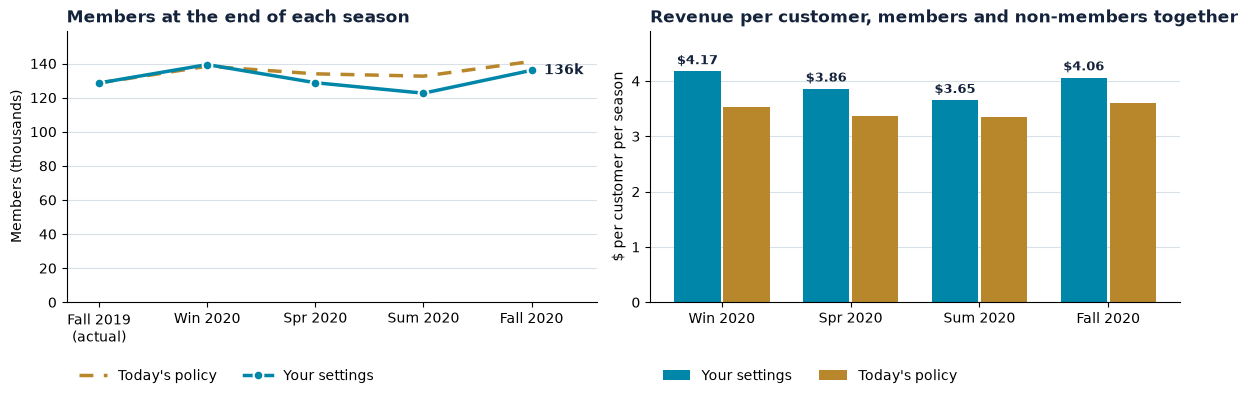

In [5]:
tu.plot(ctx, mine)

### Which settings bring in the most?

Every joining and member discount at your base price and offer share, ranked by four-season revenue per customer. "Next 4 seasons" is the same setting run for four more seasons: a setting that gains now by losing members shows up there.

In [6]:
tu.best_settings(ctx, BASE_PRICE, SHARE_OFFERED)

Top 10 of 36 settings at a $12 base with 25% of non-members offered. Today's policy: $13.85 per customer, 141,272 members at the end.


,Joining discount,Member discount,"Revenue per customer, 4 seasons",vs today,Members at the end,Members vs today,"Next 4 seasons, vs today"
1,$5,$1,$15.75,+13.7%,"136,039","-5,233",+11.3%
2,$5,$0,$15.63,+12.9%,"125,156","-16,116",+6.9%
3,$4,$1,$15.43,+11.4%,"130,531","-10,741",+7.5%
4,$5,$2,$15.40,+11.2%,"145,721","+4,449",+12.2%
5,$4,$0,$15.33,+10.7%,"120,080","-21,193",+3.6%
6,$3,$1,$15.11,+9.1%,"125,507","-15,765",+3.8%
7,$4,$2,$15.06,+8.8%,"139,726","-1,546",+8.0%
8,$3,$0,$15.02,+8.5%,"115,369","-25,903",+0.3%
9,$2,$1,$14.81,+7.0%,"121,277","-19,996",+0.5%
10,$2,$0,$14.73,+6.4%,"111,303","-29,969",-2.9%


### Does the best setting depend on the advertising?

The same ranking with advertising copied from each past year in turn. If the top settings stay on top in every column, the pricing advice does not hinge on the marketing assumption. "Worst rank" is a setting's lowest place across the three years.

In [7]:
tu.robustness(ctx, BASE_PRICE, SHARE_OFFERED)

Four-season revenue per customer against today's policy, at a $12 base with 25% offered, under each past year's advertising.
Best setting: 2017: $5 to join, $1 for members; 2018: $5 to join, $1 for members; 2019: $5 to join, $1 for members.


,"2017 ads (podcast 124, social 45)","2018 ads (podcast 137, social 43)","2019 ads (podcast 133, social 47)",Average,Worst rank
"$5 to join, $1 for members",+13.0%,+13.5%,+13.7%,+13.4%,1
"$5 to join, $0 for members",+11.8%,+12.9%,+12.9%,+12.5%,2
"$4 to join, $1 for members",+10.8%,+11.4%,+11.4%,+11.2%,3
"$5 to join, $2 for members",+10.8%,+10.9%,+11.2%,+10.9%,4
"$4 to join, $0 for members",+9.7%,+10.8%,+10.7%,+10.4%,5
"$3 to join, $1 for members",+8.6%,+9.1%,+9.1%,+8.9%,6
"$4 to join, $2 for members",+8.5%,+8.6%,+8.8%,+8.6%,8
"$3 to join, $0 for members",+7.5%,+8.7%,+8.5%,+8.2%,8


## How far off it could be

To test it, the same method is started at the end of fall 2018 and asked to forecast 2019, a year that included the price cut. It is given 2019's actual prices (today's random \$1–\$5 off, with the \$15 base until the cut), and its advertising is taken from the same season a year earlier, exactly as the forecast takes 2019's. Nothing else from 2019 is used.

In [8]:
# The same method, started at the end of fall 2018 and asked to forecast 2019 under 2019's actual policy.
tu.backtest(ctx)

Four-season revenue per customer: $9.68 forecast against $11.04 actual (-12%).
Members: off by -5.6 to +1.6 per 100 customers.


,Ad exposure taken from,"Members, actual","Members, forecast","Revenue per customer, actual","Revenue per customer, forecast"
Season,,,,,
Win 2019,Win 2018,"81,754","61,721",$2.85,$2.07
Spr 2019,Spr 2018,"87,153","69,624",$2.20,$1.76
Sum 2019,Sum 2018,"100,959","106,730",$2.60,$2.88
Fall 2019,Fall 2018,"128,602","116,318",$3.40,$2.97


**Reading**

* **The forecast ran low.** Four-season revenue per customer came out 12% under actual (\$9.68 against \$11.04). Members were 4.9 to 5.6 per 100 customers too low in winter and spring, and 1.6 too high in summer. The test uses 2019's actual policy and the forecast's own advertising rule, so this is the method's real track record. The forecast prints this lean next to its headline.
* **Expect the levels above to lean low by a similar amount.** The gap between two settings is steadier, because the same lean applies to both.
* **What the test does not show.** It uses the same models as the forecast, and those have since seen 2019. So it checks the season-by-season method, not models that had never seen that year.
* **Two known soft spots.** Deep joining discounts look somewhat better here than they are. The cancellation model treats a low joining price like any low price paid last season, but members who joined at \$7–\$8 cancel about 4 points more at their first renewal than it predicts (24.7% against about 21%). As a bound: if joiners got no benefit at all from their low first price, \$5 off to join with \$1 off for members would bring in \$15.47 per customer instead of \$15.75, still well ahead of today's \$13.85. And offering the discount to everyone goes well beyond the quarter of non-members who have ever been offered one.